In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import pytesseract
from IPython.display import display
from PIL import Image

from doc_verify.config import DATA_DIR
from doc_verify.tobacco import load_tobacco, to_200_dpi
from sad_syn.analysis import (
    ablate_leave_one_out,
    ablate_one_at_a_time,
    compare_candidates,
    compare_confidence,
    font_test,
    label_gap_tests,
    ocr_accuracy,
    strength_summary,
)
from sad_syn.degrade import degrade
from sad_syn.doc_types import DOC_TYPES, render_document, rule_test
from sad_syn.generate import (
    make_clean_offer,
    make_inconsistent_offer,
    make_letters,
    set_seed,
)
from sad_syn.ocr import check_ocr, page_confidences
from sad_syn.pipeline import DEGRADE_SEED, run_ocr, run_ocr_sampled, swapped_seeds
from sad_syn.render import render_offer, template_01
from sad_syn.templates import FONTS, split_templates

set_seed(42)

samples_dir = DATA_DIR / "samples"
samples_dir.mkdir(parents=True, exist_ok=True)

In [2]:
for doc_type in DOC_TYPES:
    print(doc_type, rule_test(doc_type, 1000))

offer_letter {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


transcript {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


bank_statement {'clean': 1000, 'altered_date': 1000, 'altered_amount': 1000, 'institution_mismatch': 1000, 'total_mismatch': 1000}


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/clean_letter.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/altered_amount_letter.png


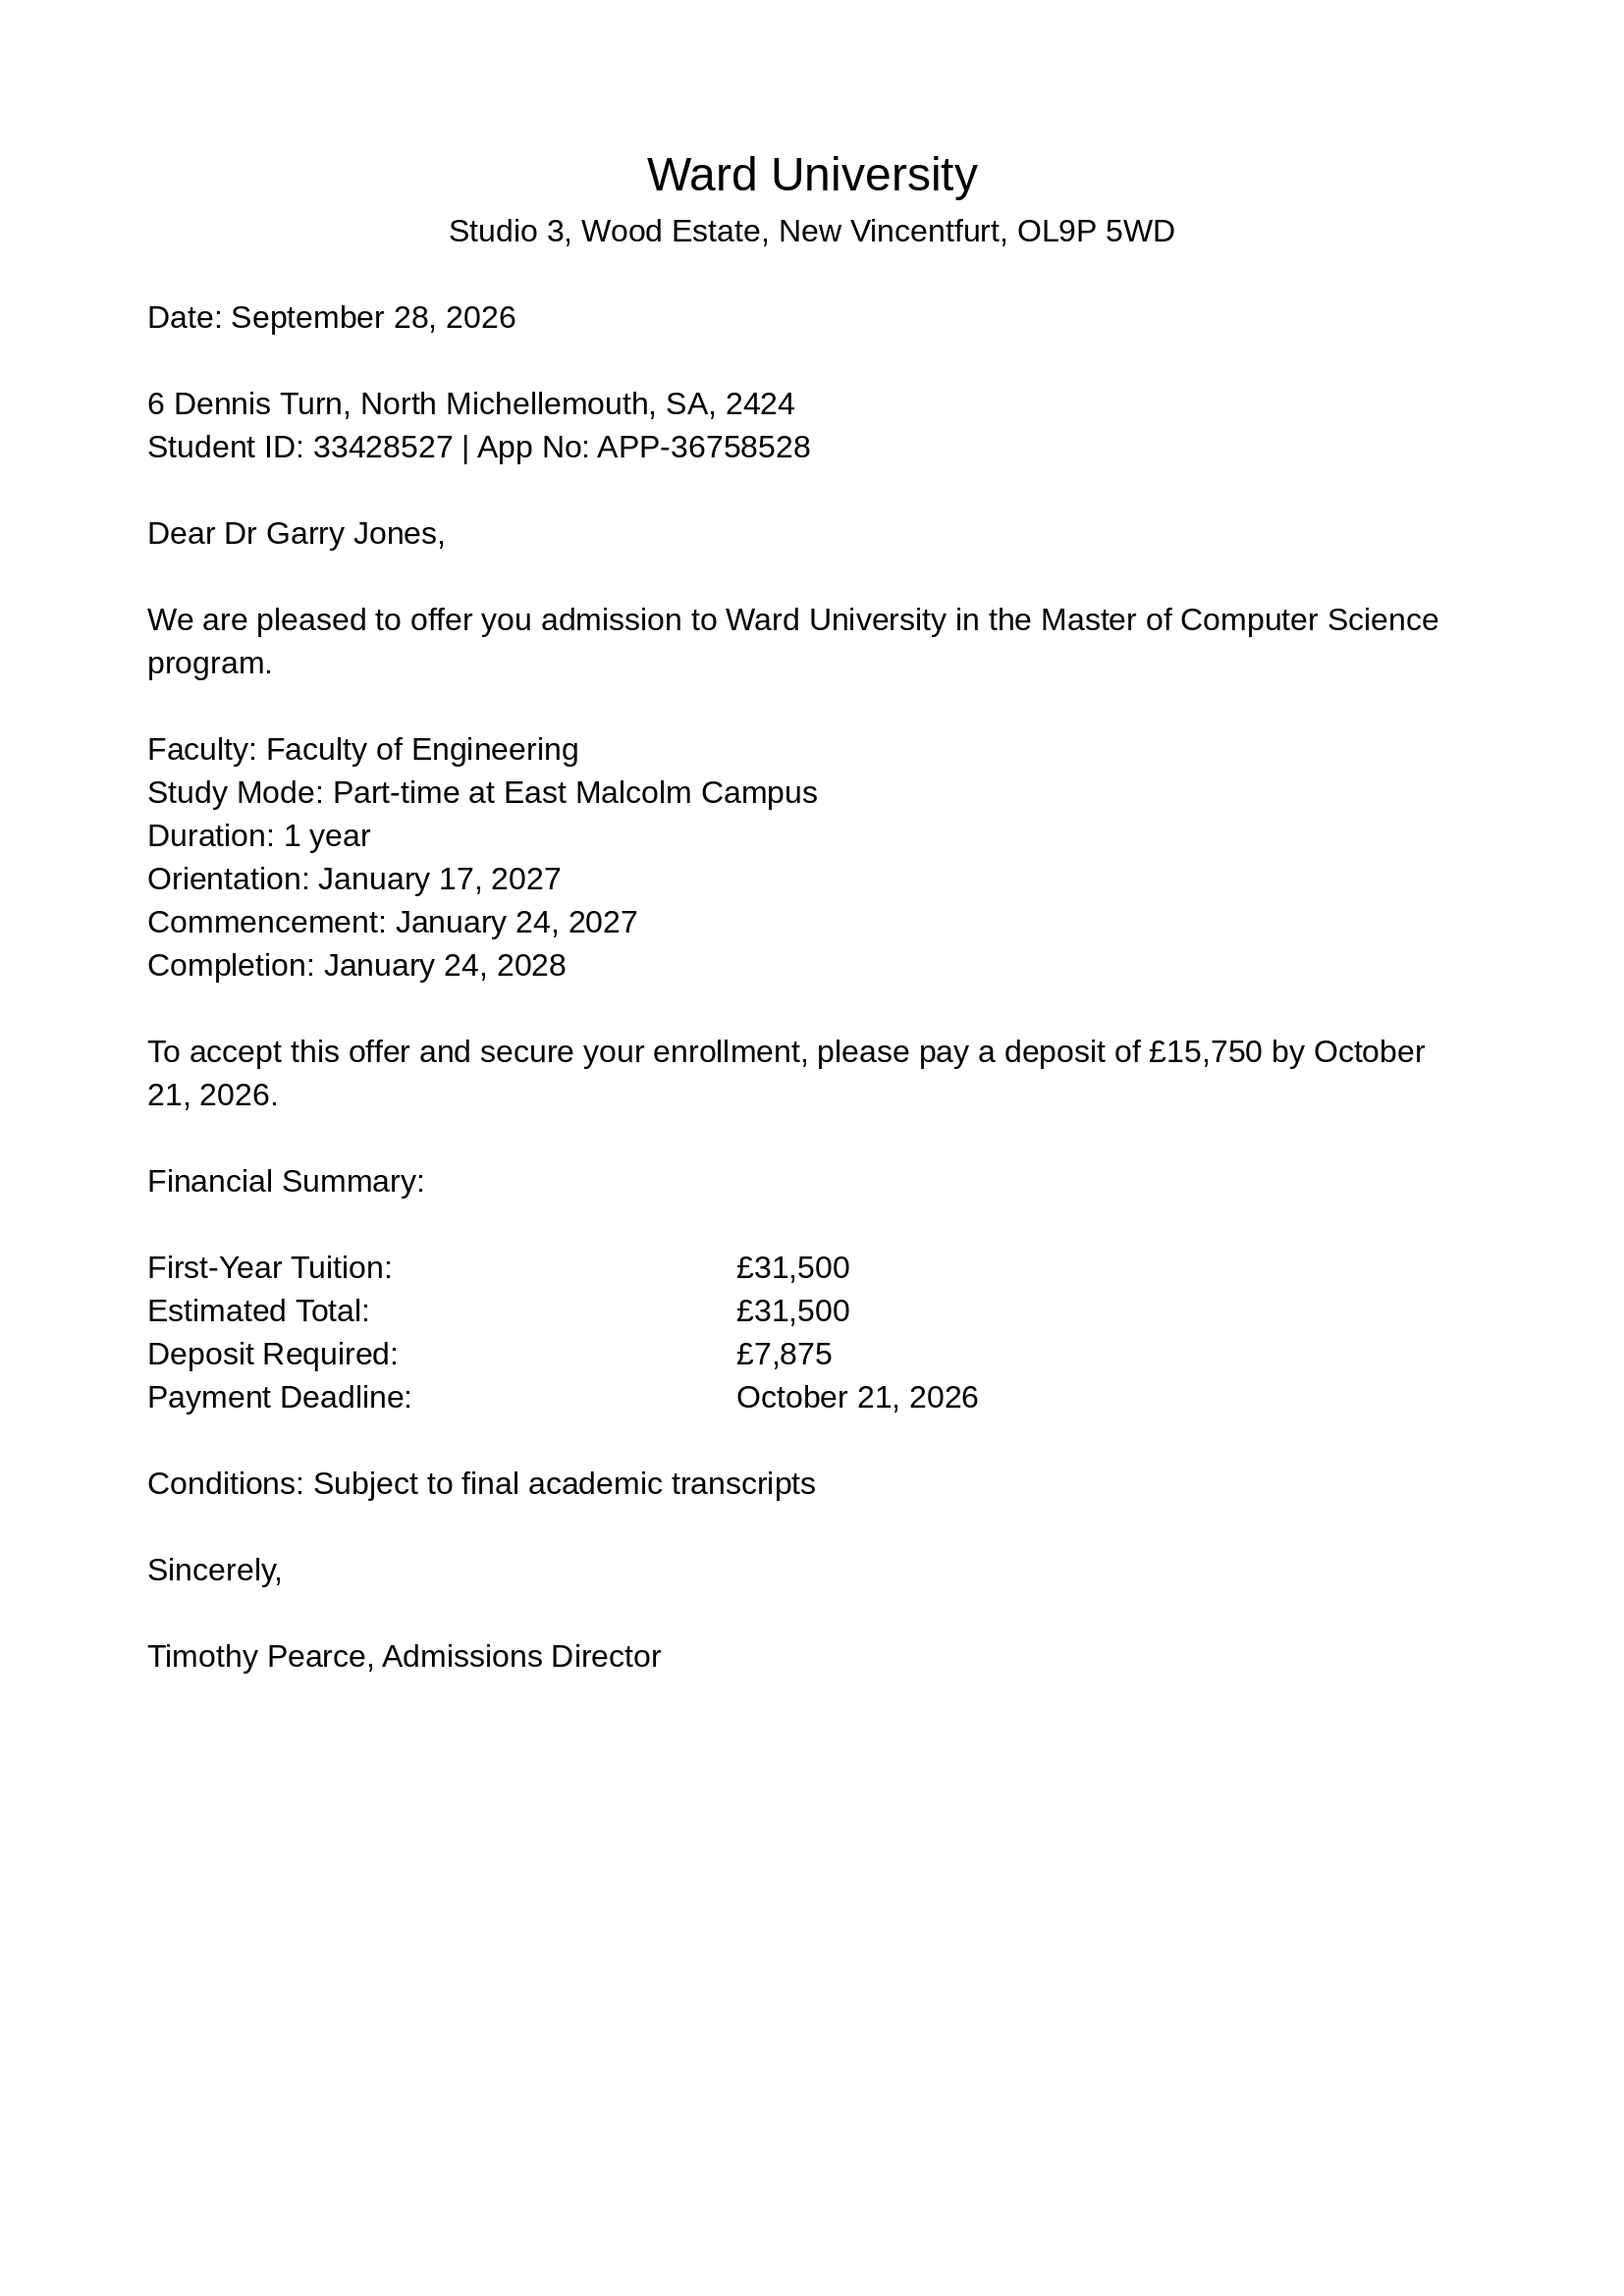

In [3]:
clean_offer = make_clean_offer()
altered_offer = make_inconsistent_offer("altered_amount")

clean_path = samples_dir / "clean_letter.png"
altered_path = samples_dir / "altered_amount_letter.png"

render_offer(clean_offer, template_01, clean_path)
render_offer(altered_offer, template_01, altered_path)

In [4]:
clean_text = pytesseract.image_to_string(Image.open(clean_path))
altered_text = pytesseract.image_to_string(Image.open(altered_path))

print(clean_text)
print("=" * 80)
print(altered_text)

University of Allanside
Flat 4, Bartlett Mount, Bernardport, W15 OET

Date: May 27, 2026

131 Johnson Quadrangle, Patrickburgh, ACT, 4388
Student ID: 40611780 | App No: APP-90552823

Dear Steven Jennings,

We are pleased to offer you admission to University of Allanside in the Master of Business
Administration program.

Faculty: Faculty of Business

Study Mode: Part-time at West Dianemouth Campus
Duration: 1 year

Orientation: September 07, 2026

Commencement: September 14, 2026

Completion: September 14, 2027

To accept this offer and secure your enrollment, please pay a deposit of £4,450 by June 15,
2026.

Financial Summary:

First-Year Tuition: £44,500
Estimated Total: £44,500
Deposit Required: £4,450
Payment Deadline: June 15, 2026

Conditions: None
Sincerely,

Jack Harris, Admissions Director

Ward University
Studio 3, Wood Estate, New Vincentfurt, OL9P 5WD

Date: September 28, 2026

6 Dennis Turn, North Michellemouth, SA, 2424
Student ID: 33428527 | App No: APP-36758528

Dear Dr 

In [5]:
print("clean missing:", check_ocr(clean_offer, clean_text, template_01))
print("altered missing:", check_ocr(altered_offer, altered_text, template_01))

clean missing: {}
altered missing: {}


In [6]:
set_seed(42)
for doc_type, kind in DOC_TYPES.items():
    doc = kind.make_inconsistent("altered_amount")
    for template in kind.templates[:3]:
        render_document(doc, template, samples_dir / f"{template['template_id']}.png")

Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_letter_01.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_letter_02.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/offer_letter_03.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_01.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_02.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/transcript_03.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_statement_01.png


Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_statement_02.png
Saved: /Users/sauravupreti/Documents/Adelaide University/COMP_6001/Final project/doc-verify/data/samples/bank_statement_03.png


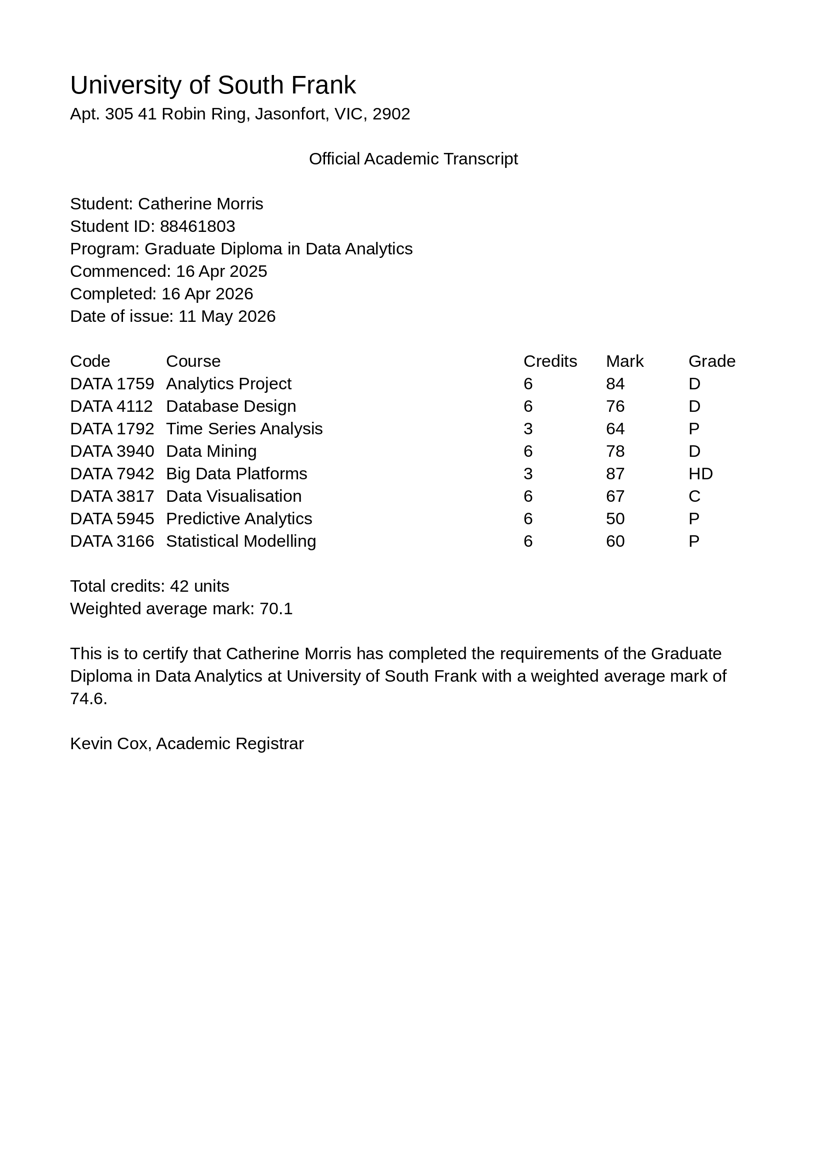

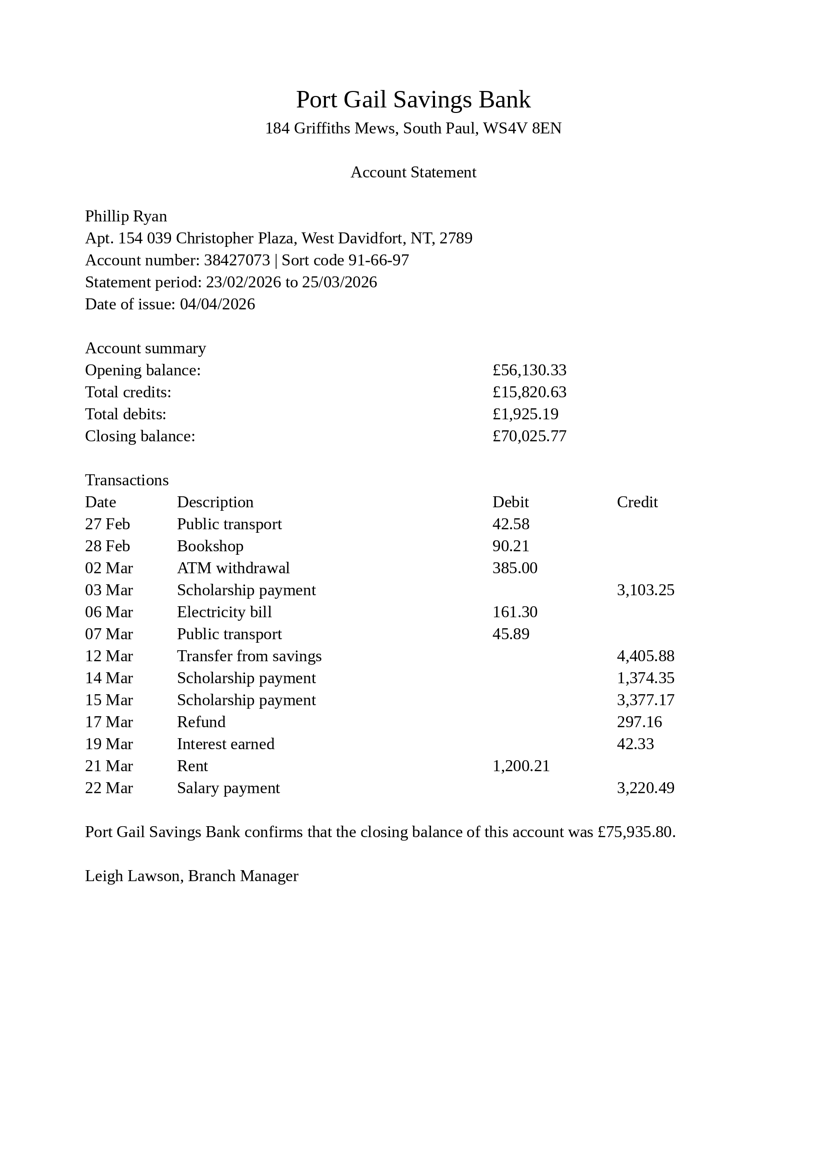

In [7]:
for name in ["transcript_01", "bank_statement_02"]:
    page = Image.open(samples_dir / f"{name}.png")
    display(page.resize((page.width // 2, page.height // 2)))

In [8]:
template_rows = [
    {'doc_type': doc_type, 'split': split, **template}
    for doc_type, kind in DOC_TYPES.items()
    for split, templates in split_templates(doc_type, kind.templates).items()
    for template in templates
]
template_table = pd.DataFrame(template_rows)

display(template_table.groupby(['doc_type', 'split']).size().unstack()[['train', 'val', 'test']])
template_table.groupby(['split', 'font']).size().unstack(fill_value=0)

split,train,val,test
doc_type,,,
bank_statement,14,3,3
offer_letter,14,3,3
transcript,14,3,3


font,Lato-Regular.ttf,LiberationSans-Regular.ttf,LiberationSerif-Regular.ttf,PTSans-Regular.ttf,PTSerif-Regular.ttf
split,,,,,
test,2,3,0,2,2
train,10,7,9,9,7
val,0,2,3,1,3


In [9]:
font_test(FONTS).round(3).T

font,LiberationSans-Regular.ttf,LiberationSerif-Regular.ttf,PTSans-Regular.ttf,PTSerif-Regular.ttf,Lato-Regular.ttf
offer_letter clean,1.000,0.975,1.000,1.000,1.000
offer_letter degraded,0.912,0.919,0.960,0.933,0.954
transcript clean,0.975,1.000,0.975,1.000,1.000
transcript degraded,0.959,0.959,0.959,0.962,0.953
bank_statement clean,0.950,0.975,1.000,1.000,0.975
bank_statement degraded,0.870,0.900,0.928,0.900,0.920


In [10]:
STRENGTHS = [0, 0.25, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 1]

set_seed(42)
offers = make_letters(100)
sweep = run_ocr(offers, template_01, STRENGTHS)

for strength in STRENGTHS:
    degrade(render_offer(offers[0], template_01), strength, DEGRADE_SEED).save(samples_dir / f"degrade_{strength:.2f}.png")

strength_summary(sweep)

,copies_read,copies_total,altered_value_ocr_ok,ocr_accuracy
strength,,,,
0.00,1200,1200,1.0,1.000000
0.25,1187,1200,1.0,0.989167
0.50,1186,1200,1.0,0.988333
0.55,1184,1200,0.98,0.986667
0.60,1169,1200,0.98,0.974167
0.65,1173,1200,0.98,0.977500
0.70,1173,1200,0.98,0.977500
0.75,1153,1200,0.94,0.960833
1.00,1100,1200,0.84,0.916667


In [11]:
set_seed(7)
gap_offers = make_letters(400)
gap = run_ocr(gap_offers, template_01, [0.5, 0.75])

ocr_accuracy(gap, ['strength', 'label']).unstack()

label,altered,clean
strength,,
0.50,0.981250,0.986667
0.75,0.945833,0.949583


In [12]:
label_gap_tests(gap)

,clean,altered,letters_per_group,z_test_p (copies as units),welch_t_p (letters as units)
strength,,,,,
0.50,0.986667,0.981250,200,0.135302,0.126620
0.75,0.949583,0.945833,200,0.559532,0.623173


In [13]:
gap_swapped = run_ocr(gap_offers, template_01, [0.75], seeds=swapped_seeds(len(gap_offers)))

pd.DataFrame({
    'original seeds': ocr_accuracy(gap[gap['strength'] == 0.75], 'label'),
    'swapped seeds': ocr_accuracy(gap_swapped, 'label'),
})

,original seeds,swapped seeds
label,,
altered,0.945833,0.95250
clean,0.949583,0.95625


In [14]:
ablate_one_at_a_time(offers, template_01, 0.75)

all effects        0.960833
rotation only      1.000000
blur only          1.000000
resolution only    1.000000
noise only         1.000000
stroke only        1.000000
threshold only     1.000000
specks only        0.987500
Name: ocr_accuracy, dtype: float64

In [15]:
ablate_leave_one_out(offers, template_01, 0.75)

all effects           0.960833
without rotation      0.969167
without blur          0.961667
without resolution    0.986667
without noise         0.956667
without stroke        0.966667
without threshold     0.974167
without specks        0.974167
Name: ocr_accuracy, dtype: float64

In [16]:
tobacco_letters = load_tobacco('Letter')
tobacco_conf = pd.Series(page_confidences(to_200_dpi(ex['image']) for ex in tobacco_letters), name='tobacco')

print(f"{len(tobacco_conf)} Tobacco letters, {tobacco_conf.isna().sum()} with no text found")
tobacco_conf.describe()

567 Tobacco letters, 0 with no text found


count    567.000000
mean      88.250195
std        6.092167
min       45.342593
25%       85.717763
50%       90.333333
75%       92.347945
max       95.345291
Name: tobacco, dtype: float64

In [17]:
compare_confidence(sweep, tobacco_conf, 'tobacco').round(3)

,no_text,q10,q25,q50,q75,q90,ks_vs_reference
tobacco,0.0,80.833,85.718,90.333,92.348,93.566,0.000
sad-syn 0.0,0.0,95.115,95.189,95.288,95.364,95.440,0.979
sad-syn 0.25,0.0,92.320,93.331,93.957,94.689,95.093,0.673
sad-syn 0.5,0.0,90.400,91.653,92.834,93.685,94.319,0.445
sad-syn 0.55,0.0,90.115,91.825,92.992,93.740,94.245,0.454
sad-syn 0.6,0.0,90.017,91.022,92.463,93.475,94.298,0.397
sad-syn 0.65,0.0,88.723,90.747,92.165,93.139,93.925,0.320
sad-syn 0.7,0.0,89.114,90.063,91.477,92.733,93.646,0.306
sad-syn 0.75,0.0,88.420,89.508,91.214,92.738,93.846,0.274
sad-syn 1.0,0.0,83.494,86.849,89.098,91.108,92.560,0.189


In [18]:
CANDIDATES = {
    'A: uniform 0.6-1.0': [(1, 0.6, 1.0)],
    'B: uniform 0.7-1.2': [(1, 0.7, 1.2)],
    'C: 75% 0.6-0.9 + 25% 0.9-1.4': [(0.75, 0.6, 0.9), (0.25, 0.9, 1.4)],
}

set_seed(11)
candidate_offers = make_letters(400)
candidate_results = {name: run_ocr_sampled(candidate_offers, template_01, mixture) for name, mixture in CANDIDATES.items()}

compare_candidates(candidate_results, tobacco_conf, 'tobacco').round(3)

,ks_vs_reference,mean_strength,no_text,ocr_accuracy,q10,q25,q50,q75,q90
tobacco,0.000,NaN,0.0,NaN,80.833,85.718,90.333,92.348,93.566
A: uniform 0.6-1.0,0.212,0.804,0.0,0.949,86.860,88.866,91.008,92.831,93.818
B: uniform 0.7-1.2,0.107,0.955,0.0,0.903,81.993,86.309,89.356,92.000,93.359
C: 75% 0.6-0.9 + 25% 0.9-1.4,0.170,0.845,0.0,0.923,85.449,88.603,90.835,92.623,93.744


In [19]:
pd.DataFrame({name: ocr_accuracy(results, 'label') for name, results in candidate_results.items()})

,A: uniform 0.6-1.0,B: uniform 0.7-1.2,C: 75% 0.6-0.9 + 25% 0.9-1.4
label,,,
altered,0.952917,0.913333,0.913333
clean,0.945833,0.892083,0.932917


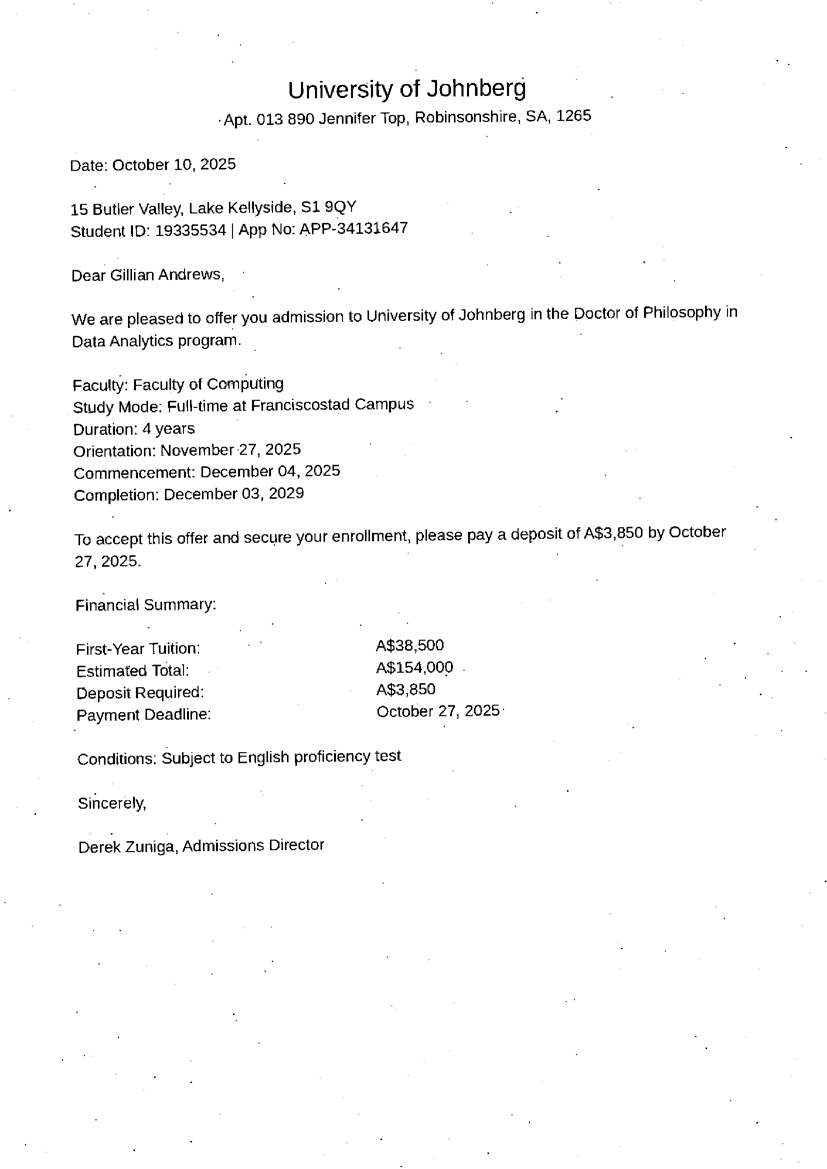

In [20]:
example = Image.open(samples_dir / "degrade_0.50.png")
display(example.resize((example.width // 2, example.height // 2)))

In [21]:
manifest = pd.read_csv(DATA_DIR / "sad_syn" / "manifest.csv")
manifest['accuracy'] = manifest['copies_read'] / manifest['copies_total']

display(manifest.groupby(['split', 'doc_type', 'label']).size().unstack())
display(manifest.groupby(['doc_type', 'split']).agg(
    templates=('template', 'nunique'),
    images=('label', 'size'),
    ocr_accuracy=('accuracy', 'mean'),
    median_confidence=('mean_confidence', 'median'),
    altered_value_ocr_ok=('altered_value_ocr_ok', 'mean'),
).round(3))

manifest.groupby(['doc_type', 'template'])['accuracy'].mean().groupby('doc_type').agg(['min', 'median', 'max']).round(3)

label                 altered  clean
split doc_type                      
test  bank_statement       75     75
      offer_letter         75     75
      transcript           75     75
train bank_statement      350    350
      offer_letter        350    350
      transcript          350    350
val   bank_statement       75     75
      offer_letter         75     75
      transcript           75     75

templates  images  ocr_accuracy  median_confidence  \
doc_type       split                                                       
bank_statement test           3     150         0.873             84.579   
               train         14     700         0.872             85.385   
               val            3     150         0.840             84.396   
offer_letter   test           3     150         0.952             91.747   
               train         14     700         0.918             90.341   
               val            3     150         0.930             90.411   
transcript     test           3     150         0.953             88.589   
               train         14     700         0.952             88.028   
               val            3     150         0.966             86.856   

                     altered_value_ocr_ok  
doc_type       split                       
bank_statement test              0.853333  
               train             0.862857  
               val                   0.84  
offer_letter   test              0.933333  
               train             0.868571  
               val               0.893333  
transcript     test              0.893333  
               train             0.942857  
               val               0.946667

,min,median,max
doc_type,,,
bank_statement,0.810,0.865,0.930
offer_letter,0.867,0.928,0.958
transcript,0.918,0.950,0.990


In [22]:
from sad_syn.degrade import draw_strength

[draw_strength(10_000) for _ in range(5)]

[0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072,
 0.7177591501302072]